# 1. Load data


In [41]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

%pip install "kagglehub[pandas-datasets]"

import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "fake_job_postings.csv"

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "shivamb/real-or-fake-fake-jobposting-prediction",
    file_path
)


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
C:\Users\Akshat\AppData\Local\Temp\ipykernel_15216\558112541.py:25: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Note: you may need to restart the kernel to use updated packages.


In [42]:
# pip show scikit-learn
from sklearn.linear_model import LogisticRegression
df.head(20)
df.shape
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

In [25]:
df.isnull().sum().sort_values(ascending=False)



salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
title                      0
job_id                     0
telecommuting              0
has_questions              0
has_company_logo           0
fraudulent                 0
dtype: int64

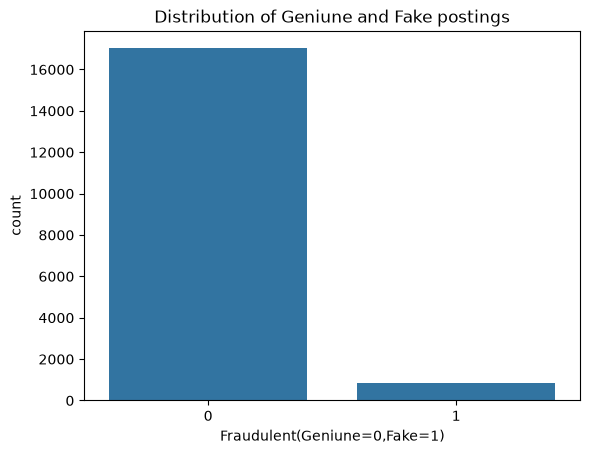

In [44]:
sns.countplot(x='fraudulent',data=df)
plt.title("Distribution of Geniune and Fake postings")
plt.xlabel("Fraudulent(Geniune=0,Fake=1)")
plt.ylabel("count")
plt.show()

### 2. Combine the text columns into one column called "text"

In [50]:
df['text']=df['title'] + ' ' + df['company_profile'] +" "+ df['description'] + " "+ df['requirements'] +" " +df["benefits"]
df['text']=df['text'].fillna('')
df['text'].isnull().sum()


np.int64(0)

In [51]:
df=df.drop(['title','company_profile','description','requirements','benefits','location','salary_range','department','job_id'],axis=1)

In [55]:
df['text'].isnull().sum()
# df['text'] = df['text'].fillna('')
df

,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,text
0,0,1,0,Other,Internship,NaN,NaN,Marketing,0,
1,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0,Customer Service - Cloud Video Production 90 S...
2,0,1,0,NaN,NaN,NaN,NaN,NaN,0,
3,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,Account Executive - Washington DC Our passion ...
4,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,Bill Review Manager SpotSource Solutions LLC i...
...,...,...,...,...,...,...,...,...,...,...
17875,0,1,1,Full-time,Mid-Senior level,NaN,Computer Software,Sales,0,Account Director - Distribution Vend is looki...
17876,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Internet,Accounting/Auditing,0,Payroll Accountant WebLinc is the e-commerce p...
17877,0,0,0,Full-time,NaN,NaN,NaN,NaN,0,
17878,0,0,1,Contract,Not Applicable,Professional,Graphic Design,Design,0,


### 3. Fill missing values in categorical columns

In [54]:
df.isnull().sum().sort_values(ascending=False)

required_education     8105
required_experience    7050
function               6455
industry               4903
employment_type        3471
telecommuting             0
has_company_logo          0
has_questions             0
fraudulent                0
text                      0
dtype: int64

In [ ]:
cat_cols=['required_education',"required_experience","function","industry","employment_type"]
df[cat_cols]=df[cat_cols].fillna("Unknown")
df[cat_cols].isnull().sum().sort_values(ascending=False)
num_cols=['telecommuting','has_questions','has_company_logo']


In [72]:
df['fraudulent'].value_counts(normalize=True)*100
# sns.countplot(x='fraudulent',data=df)
# plt.title("Distribution of Genuine and Fake Postings")
# plt.xlabel("fraudulent(Genuine=0,Fake=1)")
# plt.ylabel("count")
df

,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,text
0,0,1,0,Other,Internship,unknown,Unknown,Marketing,0,
1,0,1,0,Full-time,Not Applicable,unknown,Marketing and Advertising,Customer Service,0,Customer Service - Cloud Video Production 90 S...
2,0,1,0,Unknown,unknown,unknown,Unknown,unknown,0,
3,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,Account Executive - Washington DC Our passion ...
4,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,Bill Review Manager SpotSource Solutions LLC i...
...,...,...,...,...,...,...,...,...,...,...
17875,0,1,1,Full-time,Mid-Senior level,unknown,Computer Software,Sales,0,Account Director - Distribution Vend is looki...
17876,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Internet,Accounting/Auditing,0,Payroll Accountant WebLinc is the e-commerce p...
17877,0,0,0,Full-time,unknown,unknown,Unknown,unknown,0,
17878,0,0,1,Contract,Not Applicable,Professional,Graphic Design,Design,0,


### 4. Train / test split (stratify because fraud is rare)

In [84]:
x=df[['text'] +num_cols +cat_cols]
y=df['fraudulent']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)



Training matrix: (14304, 10000)
Testing matrix: (3576, 10000)
Vocabulary size: 10000


['contact', 'center', 'representatives', 'tidewater', 'finance', 'co', 'was', 'established', 'in', '1992', 'for', 'the', 'initial', 'purpose', 'of', 'purchasing', 'and', 'servicing', 'retail', 'installment', 'contracts', 'there', 'are', 'two', 'divisions', 'credit', 'services', 'providing', 'indirect', 'consumer']


### 5. ColumnTransformer: different processing for different columns

In [87]:
preprocessor=ColumnTransformer(
    transformers=[
        ("text",CountVectorizer(stop_words='english',max_features=5000,ngram_range=(1,2)),'text'),
        ("cat",OneHotEncoder(handle_unknown='ignore'),cat_cols),
        ("num","passthrough",num_cols)
    ]
)

### 6. Pipeline: preprocessing + model

In [97]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ],
    memory=memory
)


### 7. Evaluate

In [98]:
print(f"accuracy={accuracy_score(y_test,y_pred)}")
print(f"classification report={classification_report(y_test,y_pred)}")
print(f"confusion matrix={confusion_matrix(y_test,y_pred)}")

#hyperparamter tuning
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": ["balanced", None]
}

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=1,
    verbose=1
)

grid.fit(x_train, y_train)



accuracy=0.8884228187919463
classification report=              precision    recall  f1-score   support

           0       0.99      0.89      0.94      3403
           1       0.29      0.89      0.44       173

    accuracy                           0.89      3576
   macro avg       0.64      0.89      0.69      3576
weighted avg       0.96      0.89      0.91      3576

confusion matrix=[[3023  380]
 [  19  154]]
Fitting 5 folds for each of 8 candidates, totalling 40 fits


d:\PYTHON\projects\Fakejob detector\venv\Lib\site-packages\joblib\memory.py:616: UserWarning: Persisting input arguments took 1.12s to run.If this happens often in your code, it can cause performance problems (results will be correct in all cases). The reason for this is probably some large input arguments for a wrapped function.
  return self._cached_call(args, kwargs, shelving=False)[0]


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(memo..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...], 'classifier__class_weight': ['balanced', None]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digit

In [101]:
best_param=grid.best_params_
best_model=grid.best_estimator_
best_score=grid.best_score_
print(f'Best Parameters:{best_param}')
print(f'Best model:{best_model}')
print(f'Best score:{best_score}')


Best Parameters:{'classifier__C': 10, 'classifier__class_weight': None}
Best model:Pipeline(memory=Memory(location=./pipeline_cache\joblib),
         steps=[('preprocessor',
                 ColumnTransformer(transformers=[('text',
                                                  CountVectorizer(max_features=5000,
                                                                  ngram_range=(1,
                                                                               2),
                                                                  stop_words='english'),
                                                  'text'),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['required_education',
                                                   'required_experience',
                                                   'function', 'industry',
 

In [107]:
#best model evaluation
best_model.fit(x_train,y_train)
y_pred_tuned=best_model.predict(x_test)

# print(f'accuracy score={accuracy_score(y_test,y_pred_tuned)}')
# print(f'classification report ={classification_report(y_test,y_pred_tuned)}')
# print(f'confusion matrix ={confusion_matrix(y_test,y_pred_tuned)}')

In [110]:
y_test_prob = best_model.predict_proba(x_test)[:, 1]
threshold = 0.3

y_test_final = (y_test_prob >= threshold).astype(int)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("Threshold:", threshold)
print("Accuracy:", accuracy_score(y_test, y_test_final))
print("Fraud Precision:", precision_score(y_test, y_test_final))
print("Fraud Recall:", recall_score(y_test, y_test_final))
print("Fraud F1:", f1_score(y_test, y_test_final))

print("\nClassification Report:")
print(classification_report(y_test, y_test_final))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_final))

Threshold: 0.3
Accuracy: 0.9751118568232662
Fraud Precision: 0.868421052631579
Fraud Recall: 0.5722543352601156
Fraud F1: 0.6898954703832753

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3403
           1       0.87      0.57      0.69       173

    accuracy                           0.98      3576
   macro avg       0.92      0.78      0.84      3576
weighted avg       0.97      0.98      0.97      3576


Confusion Matrix:
[[3388   15]
 [  74   99]]


In [103]:


x_subtrain, x_val, y_subtrain, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [104]:
from sklearn.base import clone

validation_model = clone(grid.best_estimator_)

validation_model.fit(x_subtrain, y_subtrain)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",Memory(locati..._cache\joblib)
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['text','telecommuting','has_questions',...,'function','industry', 'employment_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

In [105]:
y_prob = validation_model.predict_proba(x_val)[:, 1]

In [106]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:

    y_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_threshold)
    recall = recall_score(y_val, y_threshold)
    f1 = f1_score(y_val, y_threshold)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1 Score: {f1:.3f}")


Threshold: 0.1
Precision: 0.349
Recall: 0.849
F1 Score: 0.495

Threshold: 0.2
Precision: 0.479
Recall: 0.755
F1 Score: 0.587

Threshold: 0.3
Precision: 0.696
Recall: 0.561
F1 Score: 0.622

Threshold: 0.4
Precision: 0.753
Recall: 0.460
F1 Score: 0.571

Threshold: 0.5
Precision: 0.784
Recall: 0.417
F1 Score: 0.545

Threshold: 0.6
Precision: 0.831
Recall: 0.388
F1 Score: 0.529

Threshold: 0.7
Precision: 0.852
Recall: 0.374
F1 Score: 0.520


### 8. Save

In [118]:
import joblib
joblib.dump(best_model,"fake_Job_detector.pkl")

['fake_Job_detector.pkl']

In [114]:
import os

print(os.path.exists("fake_job_detector.pkl"))

True


In [ ]:
missed_indices = missed_frauds.index

missed_jobs = df.loc[
    missed_indices,
    ["title", "description", "requirements", "fraudulent"]
]

missed_jobs.head(10)

KeyError: "['title', 'description', 'requirements'] not in index"

In [116]:
sample = x_test.iloc[[0]]

original_prediction = best_model.predict(sample)
loaded_prediction = loaded_model.predict(sample)

print("Original model:", original_prediction)
print("Loaded model:", loaded_prediction)

Original model: [0]
Loaded model: [0]


In [117]:
probability = loaded_model.predict_proba(sample)[0][1]

threshold = 0.3
prediction = int(probability >= threshold)

print("Fraud probability:", probability)
print("Prediction:", prediction)

if prediction == 1:
    print("⚠️ Potential fraudulent job posting")
else:
    print("✅ Likely genuine job posting")

Fraud probability: 0.0003041656533492857
Prediction: 0
✅ Likely genuine job posting


In [123]:
import os

print(os.path.abspath("fake_job_detector.pkl"))
print(os.path.getsize("fake_job_detector.pkl"))

d:\PYTHON\projects\Fakejob detector\fake_job_detector.pkl
211216
